# KDD — Discovering card usage segments

CMPE-255 • Data mining process assignment • November 3, 2026

Run all cells in order. This notebook is self-contained and Colab-compatible. It uses the bundled CSV when present; otherwise it downloads the exact public Kaggle dataset and checks its SHA-256. Figures, fitted pipelines, and evaluation tables are written to `artifacts/`. Results stored in this notebook were executed locally; a hosted Colab run remains a separate verification. AI assistance: Codex; see the review record and student verification checklist.

## Setup
A CPU runtime is sufficient. In a fresh Colab runtime, run the optional installation cell, then restart the runtime if an installed library was already imported. Pinned dependencies match the verified local run. No API key is required.

In [1]:
# Optional fresh-runtime installation (uncomment if needed):
# %pip install numpy==2.0.2 pandas==2.3.3 scikit-learn==1.6.1 matplotlib==3.9.4 joblib==1.5.3 requests==2.32.5 tabulate==0.9.0

In [2]:
from pathlib import Path
import io, json, hashlib, zipfile, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib, requests
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, GroupShuffleSplit, GroupKFold
from sklearn.metrics import *
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (9,5), 'axes.spines.top':False, 'axes.spines.right':False})
ART = Path('artifacts'); ART.mkdir(exist_ok=True)
def save_json(name, value):
    (ART/name).write_text(json.dumps(value, indent=2, default=lambda x: x.item() if hasattr(x,'item') else str(x)))
def figure(name):
    plt.tight_layout(); plt.savefig(ART/name, dpi=150, bbox_inches='tight'); plt.show(); plt.close()
def load_kaggle(slug, filename, expected):
    path = Path('data')/filename
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        response=requests.get('https://www.kaggle.com/api/v1/datasets/download/'+slug, timeout=120)
        response.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(response.content)) as z:
            matches=[n for n in z.namelist() if Path(n).name == filename]
            if len(matches)!=1: raise ValueError('Expected exactly one matching CSV in archive')
            path.write_bytes(z.read(matches[0]))
    actual=hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual == expected, 'Dataset version changed; inspect before continuing'
    print('Verified SHA-256:',actual)
    return pd.read_csv(path)
def quality_report(df):
    out=pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique()})
    out.to_csv(ART/'data_quality.csv'); display(out)
    print('Rows:',len(df),'Exact duplicates:',int(df.duplicated().sum()))
def bootstrap_ci(y, pred, metric, n=500):
    rng=np.random.default_rng(SEED); y=np.asarray(y); pred=np.asarray(pred); vals=[]
    for _ in range(n):
        ix=rng.integers(0,len(y),len(y))
        try: vals.append(metric(y[ix],pred[ix]))
        except ValueError: pass
    return np.quantile(vals,[.025,.975]).tolist()
save_json('environment.json',{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scikit_learn':sklearn.__version__,'seed':SEED})


/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## 1. Domain understanding and discovery goal
Discover reproducible, understandable usage patterns in a historical customer dataset to inform hypothetical service-design research. A useful result must have measurable separation and stability, interpretable original-unit profiles, and a plausible follow-up question. It does not identify true customer types or prove which promotion works. No cluster is a credit-risk rating, and the prototype must not determine lending eligibility, credit limits, prices, or access to services.

This notebook uses the nine-step KDD formulation, mapped to the common five-stage diagram: selection (steps 1–2), preprocessing (3), transformation (4), data mining (5–7), and interpretation/evaluation plus knowledge use (8–9). KDD is iterative; a failure of stability returns the work to representation or algorithm selection rather than just renaming clusters.

## 2. Create the target dataset — selection
Source: [Kaggle Credit Card Dataset for Clustering](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata). Each row is an anonymized customer usage summary. Monetary values, transaction counts, frequencies and tenure are available; acquisition dates, demographics, outcomes and treatment responses are not. Exclude `CUST_ID` from distance calculations. Keep it only as a local join key. No external integration is necessary.

Reserve 20% for final evaluation and 20% for representation/k selection, with 60% for discovery. This random split assesses within-source repeatability, not future-time transportability. There is no supervised target and no meaningful classification accuracy.

In [3]:
raw=load_kaggle('arjunbhasin2013/ccdata','CC GENERAL.csv','29eea6389837c40fd760c927b5782563edeff55a37824598489716bdb3563be1')
assert raw.CUST_ID.is_unique
quality_report(raw)
anomaly_count=int((raw['CASH_ADVANCE_FREQUENCY']>1).sum())
print('Cash-advance frequency values above 1:',anomaly_count)
save_json('quality_decision.json',{'cash_advance_frequency_above_one':anomaly_count,'decision':'Exclude ambiguous CASH_ADVANCE_FREQUENCY; retain CASH_ADVANCE and CASH_ADVANCE_TRX'})
features=[c for c in raw if c not in ['CUST_ID','CASH_ADVANCE_FREQUENCY']];X=raw[features].copy()
assert (X.dropna()>=0).all().all()
tr,rest=train_test_split(X.index,test_size=.4,random_state=SEED);va,te=train_test_split(rest,test_size=.5,random_state=SEED)
assert not(set(tr)&set(va) or set(tr)&set(te) or set(va)&set(te))
Xtr,Xv,Xte=X.loc[tr],X.loc[va],X.loc[te]
part=pd.Series('train',index=X.index);part.loc[va]='validation';part.loc[te]='test';pd.DataFrame({'row_id':X.index,'partition':part}).to_csv(ART/'split_manifest.csv',index=False)
print('Discovery/validation/test:',len(tr),len(va),len(te))


Verified SHA-256: 29eea6389837c40fd760c927b5782563edeff55a37824598489716bdb3563be1


,dtype,missing,unique
CUST_ID,object,0,8950
BALANCE,float64,0,8871
BALANCE_FREQUENCY,float64,0,43
PURCHASES,float64,0,6203
ONEOFF_PURCHASES,float64,0,4014
INSTALLMENTS_PURCHASES,float64,0,4452
CASH_ADVANCE,float64,0,4323
PURCHASES_FREQUENCY,float64,0,47
ONEOFF_PURCHASES_FREQUENCY,float64,0,47
PURCHASES_INSTALLMENTS_FREQUENCY,float64,0,47


Rows: 8950 Exact duplicates: 0
Cash-advance frequency values above 1: 8
Discovery/validation/test: 5370 1790 1790


## 3. Clean and preprocess
Missing `MINIMUM_PAYMENTS` and `CREDIT_LIMIT` are median-imputed from discovery rows inside the pipeline. Missing does not mean zero payments. The raw audit found eight `CASH_ADVANCE_FREQUENCY` values above 1 (maximum 1.5), contradicting the assumed proportion scale. Without source clarification, exclude this ambiguous field rather than clip or reinterpret it. Retain cash-advance amount and count. Remaining frequency/proportion fields must be within [0,1]; counts and monetary quantities must be nonnegative. There are no duplicate IDs. High spend is not automatically an error, so valid extremes remain. No source chronology is available and no time-window correction can be claimed.

Inspect discovery-only distributions and missingness. Heavy tails motivate a comparison of raw standardization with log1p plus standardization. The experiment is specified before test access.

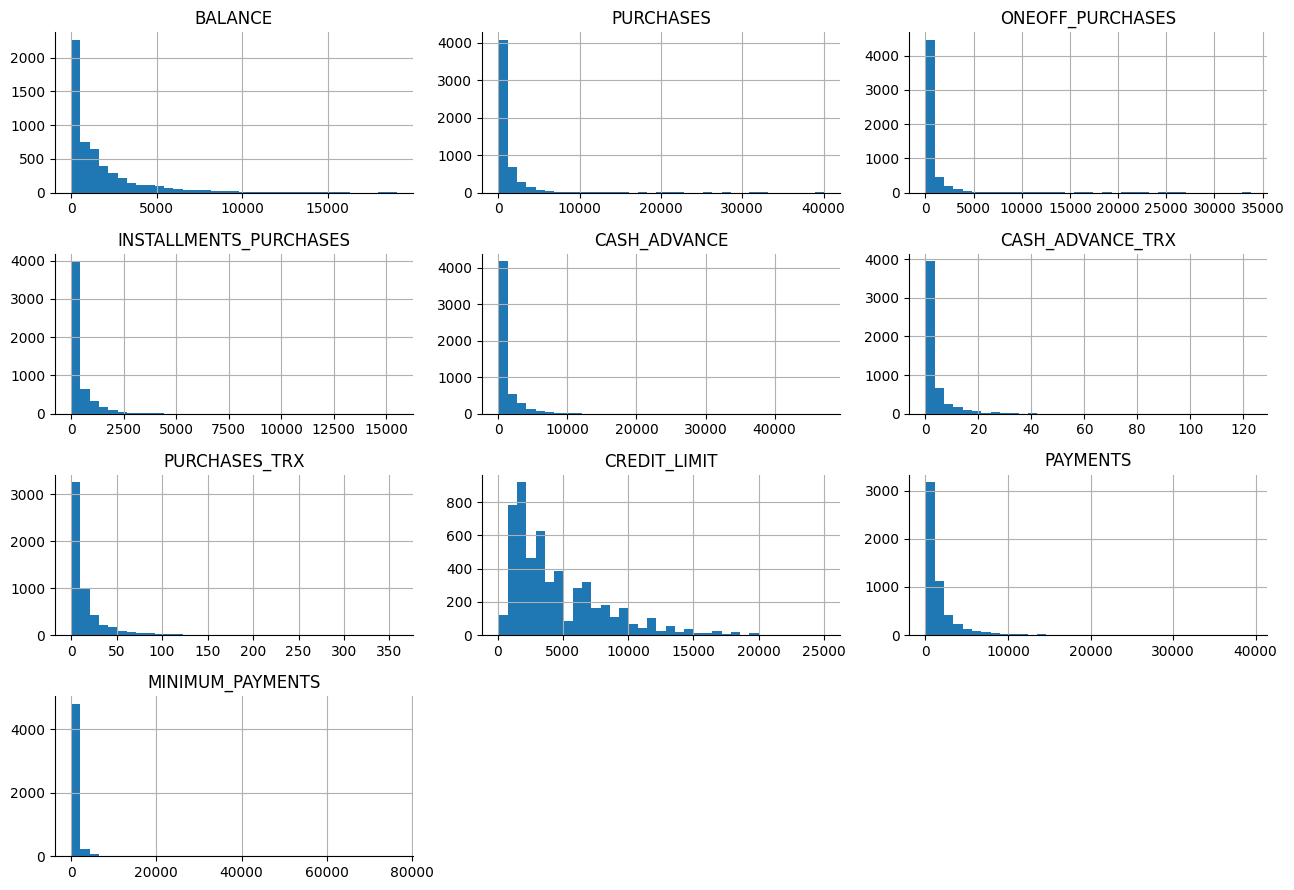

,missing,median,skew,max
BALANCE,0,884.169748,2.428484,19043.13856
BALANCE_FREQUENCY,0,1.000000,-2.012944,1.00000
PURCHASES,0,347.005000,7.488604,40040.71000
ONEOFF_PURCHASES,0,30.300000,8.451055,33803.84000
INSTALLMENTS_PURCHASES,0,88.085000,6.356793,15497.19000
CASH_ADVANCE,0,0.000000,5.684981,47137.21176
PURCHASES_FREQUENCY,0,0.500000,0.079769,1.00000
ONEOFF_PURCHASES_FREQUENCY,0,0.083333,1.576690,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,0,0.166667,0.512415,1.00000
CASH_ADVANCE_TRX,0,0.000000,5.808591,123.00000


In [4]:
frequency=[c for c in features if 'FREQUENCY' in c or c=='PRC_FULL_PAYMENT']
assert X[frequency].stack().between(0,1).all()
logcols=[c for c in features if c not in frequency+['TENURE']]
Xtr[logcols].hist(bins=35,figsize=(13,9));figure('training_distributions.png')
eda=pd.DataFrame({'missing':Xtr.isna().sum(),'median':Xtr.median(),'skew':Xtr.skew(),'max':Xtr.max()});display(eda);eda.to_csv(ART/'training_eda.csv')


## 4. Reduce/project and transform
After excluding ID and the ambiguous frequency field, the primary clustering retains all 16 eligible predictors. Money and transaction-count columns are eligible for log1p transformation; frequency and tenure columns retain their original form before standardization. Log1p handles zero and reduces heavy-tail influence. Scaling is necessary because dollars and fractions otherwise have incompatible distances.

Compare this representation with raw standardization. Both are fit solely on discovery data. PCA is later fit on transformed discovery rows for a two-dimensional plot; its explained variance is reported and the projection is not evidence of separation in all dimensions.

In [5]:
def make_pre(log=True):
    amount=Pipeline([('impute',SimpleImputer(strategy='median')),('transform',FunctionTransformer(np.log1p,feature_names_out='one-to-one') if log else FunctionTransformer(feature_names_out='one-to-one')),('scale',StandardScaler())])
    other=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
    return ColumnTransformer([('amount',amount,logcols),('other',other,[c for c in features if c not in logcols])])
save_json('schema.json',{'features':features,'numeric':features,'categorical':[],'frequency':frequency,'log_columns':logcols,'numeric_ranges':{c:[float(Xtr[c].min()),float(Xtr[c].max())] for c in features}})


## 5. Choose the mining task
The task is unsupervised clustering and descriptive profiling. Classification is inappropriate because no target is supplied. Association mining would require defensible transaction/basket semantics absent from this customer-level table; it is not added merely to generate more output.

## 6. Choose algorithms and selection rules
K-means offers reproducible nearest-centroid assignment. Compare k=2 through 6 for both representations. A diagonal-covariance Gaussian mixture with k=2 through 6 provides a different clustering assumption on the log representation. All models are trained on discovery rows and ranked by validation silhouette, subject to every validation cluster having at least 5% of rows. Silhouette prefers well-separated geometry and can favor coarse k; report this rather than forcing a visually attractive segment count. Davies–Bouldin and resampling stability provide complementary evidence. If no candidate meets the minimum share, the fallback is exploratory only.

## 7. Mine the data
Save every candidate's metrics and hyperparameters. The selected pipeline is frozen before final test evaluation. A five-resample check refits preprocessing and the algorithm on 80% discovery subsamples and compares validation assignments with the frozen solution using adjusted Rand index (ARI). This tests partition sensitivity without requiring numeric cluster IDs to align.

In [6]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
models={};rows=[]
for rep in ['raw','log']:
    pre=make_pre(rep=='log');zt=pre.fit_transform(Xtr);zv=pre.transform(Xv)
    for algorithm in (['kmeans','gmm'] if rep=='log' else ['kmeans']):
        for k in range(2,7):
            est=KMeans(n_clusters=k,n_init=20,random_state=SEED) if algorithm=='kmeans' else GaussianMixture(n_components=k,covariance_type='diag',n_init=3,reg_covar=1e-5,random_state=SEED)
            est.fit(zt);labels=est.predict(zv);key=f'{rep}_{algorithm}_{k}'
            share=np.bincount(labels,minlength=k)/len(labels)
            row={'candidate':key,'representation':rep,'algorithm':algorithm,'k':k,'silhouette':silhouette_score(zv,labels,sample_size=min(1500,len(zv)),random_state=SEED),'davies_bouldin':davies_bouldin_score(zv,labels),'minimum_share':share.min()}
            rows.append(row);models[key]=Pipeline([('pre',pre),('model',est)])
comparison=pd.DataFrame(rows);eligible=comparison[comparison.minimum_share>=.05];selection=eligible if len(eligible) else comparison
winner=selection.sort_values('silhouette',ascending=False).iloc[0]['candidate'];model=models[winner];choice=comparison.set_index('candidate').loc[winner]
comparison.to_csv(ART/'model_comparison.csv',index=False);display(comparison.sort_values('silhouette',ascending=False));print('Frozen winner:',winner)
base_labels=model.predict(Xv);aris=[]
for seed in range(5):
    idx=np.random.default_rng(seed).choice(len(Xtr),size=int(.8*len(Xtr)),replace=False)
    alternative=clone(model);alternative.set_params(model__random_state=seed);alternative.fit(Xtr.iloc[idx])
    aris.append(adjusted_rand_score(base_labels,alternative.predict(Xv)))
print('Validation resampling ARIs:',aris)


/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sali

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

... (4 outputs left out)

Frozen winner: log_kmeans_2


/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sali

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sali

Validation resampling ARIs: [0.9843875807779837, 0.966690483225497, 0.9866110701695643, 0.9910651594636805, 0.9910648845310887]


## 8. Interpret and evaluate patterns
Test silhouette and Davies–Bouldin are computed on held-out transformed rows assigned by the frozen model. The pilot proxy gate requires silhouette ≥0.20, minimum test cluster share ≥5%, and median validation resampling ARI ≥0.70. These are explicitly assumed criteria for the teaching example, not universal clustering standards.

Profiles report counts and medians in original units; a standardized profile chart aids comparison. Cluster numbers have no ordinal meaning. Profile differences are descriptive because the algorithm was designed to separate these very variables. They are not significance tests or independent causal findings. A PCA view compresses information and must be interpreted with its explained variance. Potential actions are hypotheses for stakeholder interviews and controlled tests.

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

,n,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
cluster,,,,,,,,,,,,,,,,,
0,1048,512.370380,1.0,862.22,274.08,398.285,0.000000,0.909091,0.166667,0.666667,0.0,14.0,3650.0,1003.369463,216.250721,0.0,12.0
1,742,1301.681179,1.0,0.00,0.00,0.000,915.482884,0.000000,0.000000,0.000000,3.0,0.0,3000.0,702.004588,442.235477,0.0,12.0


/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


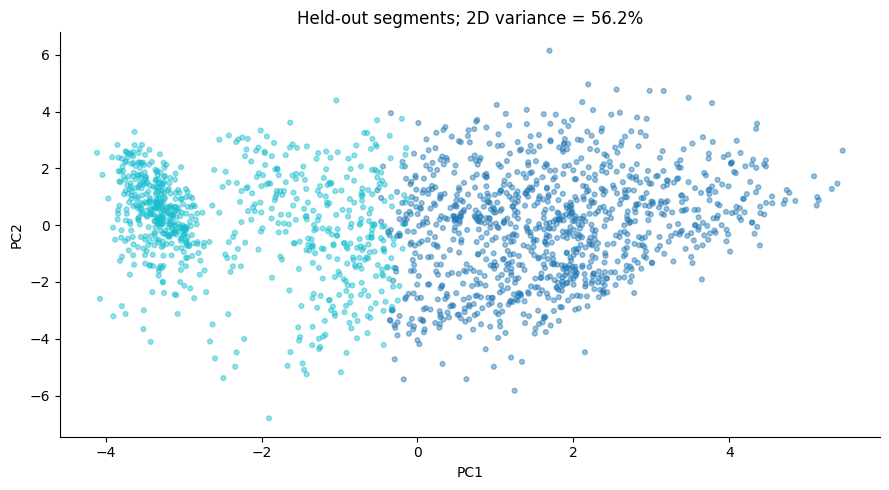

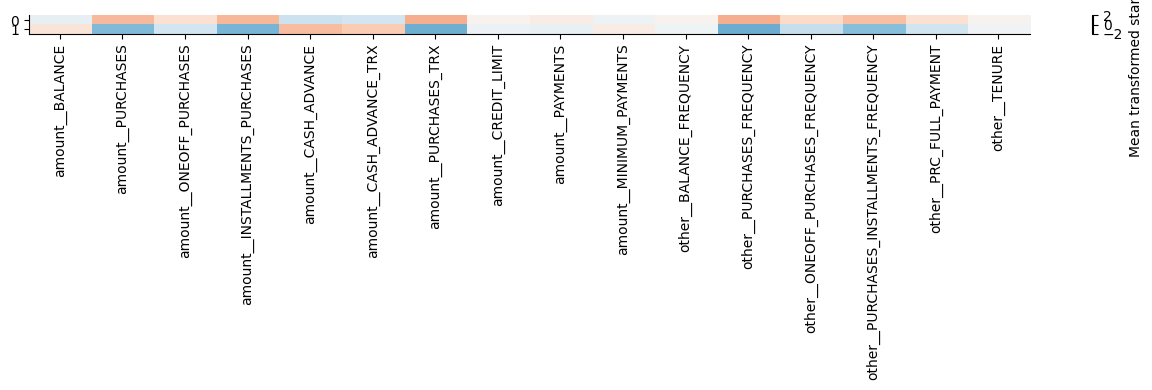

{
  "winner": "log_kmeans_2",
  "test_silhouette": 0.24629769772098267,
  "test_davies_bouldin": 1.5758513007808868,
  "test_cluster_shares": [
    0.5854748603351956,
    0.4145251396648045
  ],
  "validation_resampling_ARI": [
    0.9843875807779837,
    0.966690483225497,
    0.9866110701695643,
    0.9910651594636805,
    0.9910648845310887
  ],
  "median_ARI": 0.9866110701695643,
  "proxy_gate_passed": true,
  "PCA_2d_variance": 0.5615341728589289
}


In [7]:
ztr=model.named_steps['pre'].transform(Xtr);zte=model.named_steps['pre'].transform(Xte);labels=model.predict(Xte);k=int(choice['k'])
shares=np.bincount(labels,minlength=k)/len(labels)
metrics={'winner':winner,'test_silhouette':silhouette_score(zte,labels,sample_size=min(1500,len(zte)),random_state=SEED),'test_davies_bouldin':davies_bouldin_score(zte,labels),'test_cluster_shares':shares.tolist(),'validation_resampling_ARI':aris,'median_ARI':float(np.median(aris))}
metrics['proxy_gate_passed']=bool(metrics['test_silhouette']>=.2 and shares.min()>=.05 and np.median(aris)>=.7)
profile=Xte.assign(cluster=labels).groupby('cluster').median();profile.insert(0,'n',np.bincount(labels,minlength=k));display(profile);profile.to_csv(ART/'test_cluster_profiles.csv')
pd.DataFrame({'row_id':te,'cluster':labels}).to_csv(ART/'test_assignments.csv',index=False)
pca=PCA(n_components=2,random_state=SEED).fit(ztr);plot=pca.transform(zte);metrics['PCA_2d_variance']=float(pca.explained_variance_ratio_.sum());save_json('metrics.json',metrics)
plt.scatter(plot[:,0],plot[:,1],c=labels,cmap='tab10',s=12,alpha=.45);plt.xlabel('PC1');plt.ylabel('PC2');plt.title(f'Held-out segments; 2D variance = {metrics["PCA_2d_variance"]:.1%}');figure('test_pca.png')
scaled=pd.DataFrame(zte).assign(cluster=labels).groupby('cluster').mean()
plt.figure(figsize=(13,4));plt.imshow(scaled,aspect='auto',cmap='RdBu_r',vmin=-2,vmax=2);plt.xticks(range(zte.shape[1]),model.named_steps['pre'].get_feature_names_out(),rotation=90);plt.yticks(range(k),range(k));plt.colorbar(label='Mean transformed standardized value');figure('test_segment_heatmap.png')
print(json.dumps(metrics,indent=2))


## 9. Consolidate and act on knowledge
Deliver a report, original-unit segment profiles, a fitted assignment pipeline, a schema and a reproducible sample batch. A stakeholder can use these to design interviews about usage patterns. Do not infer debt stress, wealth, demographics or creditworthiness from cluster membership. The artifact supports service research only; no customer-level action is executed.

The local batch scorer demonstrates how new records receive cluster assignments after identical preprocessing. Proposed owner: product research analytics. Monitor monthly changes in segment shares, missingness, new numeric ranges and distance/distribution shifts; a >10 percentage-point share change or >5% missingness triggers investigation. Rerun stability checks before replacing the model, align new cluster descriptions explicitly, and retain the previous version for rollback. If the proxy gate fails, the proper next step is to revisit representation and goal with fresh data, not to claim deployable customer types.

See `report.md` for measured interpretations and `article_medium.md` for a communication draft. The next empirical step is a new, appropriately sampled dataset and stakeholder validation, followed by a controlled study of any proposed service change.

In [8]:
joblib.dump(model,ART/'model.joblib');restored=joblib.load(ART/'model.joblib');np.testing.assert_array_equal(restored.predict(Xte),labels)
Xte.iloc[:5].to_csv(ART/'sample_input.csv',index=False);pd.DataFrame({'cluster':restored.predict(Xte.iloc[:5])}).to_csv(ART/'sample_output.csv',index=False)
sample=Xte.iloc[:5].copy();sample.iloc[0,0]=np.nan;assert len(restored.predict(sample))==5
save_json('verification.json',{'disjoint_splits':True,'pipeline_roundtrip':True,'missing_input_handled':True,'all_clusters_observed':bool((shares>0).all()),'human_review_completed':False})
print('Assignment pipeline saved. Proxy gate:',metrics['proxy_gate_passed'])


Assignment pipeline saved. Proxy gate: True
